# Practica de Visualización

Un dataset de NOAA está almacenado en el archivo `data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv`. Este es el dataset que utilizaremos para la práctica.

Nota: Los datos para esta práctica forman parte de un dataset perteneciente a The data for this assignment comes from a subset of The National Centers for Environmental Information (NCEI) [Daily Global Historical Climatology Network](https://www1.ncdc.noaa.gov/pub/data/ghcn/daily/readme.txt) (GHCN-Daily). El GHCN-Daily se compone de registros climáticos diarios de miles de estaciones de la superficie terrestre en todo el mundo.

Cada fila en el archivo de datos corresponde a una sola observación.

Nos proporciona las siguientes variables:

- **id** : código de identificación de la estación
- **date** : fecha en formato YYYY-MM-DD (por ejemplo: 2012-01-24 = 24 de enero de 2012)
- **element** : indica el tipo de medición
    - **TMAX** : Temperatura máxima
    - **TMIN** : Temperatura mínima
- **value**: valor de la temperatura (en décimas de grados centígrados)

## Indicaciones

1. Lee la documentación y familiarícese con el conjunto de datos, luego escriba un código python que arroje un gráfico lineal de las temperaturas máximas y mínimas récord por día del año durante el período 2005-2014. El área entre las temperaturas máximas y mínimas récord de cada día debe estar sombreada.
2. Superponga una dispersión de los datos de 2015 para cualquier punto (máximos y mínimos) para los cuales se superó el récord de diez años (2005-2014) máximo o mínimo histórico en 2015.
3. Debes tener cuidado con los días bisiestos (es decir, el 29 de febrero), es totalmente razonable eliminar estos puntos del conjunto de datos para esta visualización.
4. ¡Haz que la imagen sea agradable! Considera problemas como leyendas, etiquetas y líneas en demasía.

Los datos proporcionados están cerca de **Ann Arbor, Michigan, Estados Unidos**.

### Carga de datos
Se importan las librerías necesarias y se carga el archivo CSV con las observaciones de temperatura. Se muestran las primeras filas para revisar la estructura del dataset.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

datos = pd.read_csv('../data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv')
datos.head()


,ID,Date,Element,Data_Value
0,USW00094889,2014-11-12,TMAX,22
1,USC00208972,2009-04-29,TMIN,56
2,USC00200032,2008-05-26,TMAX,278
3,USC00205563,2005-11-11,TMAX,139
4,USC00200230,2014-02-27,TMAX,-106


### Preparación de los datos
Se separa la fecha en año y día del año (mes-día). Se convierten las temperaturas de décimas de grado a grados centígrados. Se eliminan los registros del 29 de febrero para evitar problemas con los años bisiestos.

In [11]:
datos['Anio'] = datos['Date'].str[:4]
datos['Dia'] = datos['Date'].str[5:]
datos['Temperatura'] = datos['Data_Value'] / 10

datos = datos[datos['Dia'] != '02-29']
datos.head()

,ID,Date,Element,Data_Value,Anio,Dia,Temperatura
0,USW00094889,2014-11-12,TMAX,22,2014,11-12,2.2
1,USC00208972,2009-04-29,TMIN,56,2009,04-29,5.6
2,USC00200032,2008-05-26,TMAX,278,2008,05-26,27.8
3,USC00205563,2005-11-11,TMAX,139,2005,11-11,13.9
4,USC00200230,2014-02-27,TMAX,-106,2014,02-27,-10.6


### Récords de temperatura 2005-2014
Se separan los datos del período 2005-2014 y los del año 2015. Para el período 2005-2014 se calcula, para cada día del año, la temperatura máxima más alta y la temperatura mínima más baja registradas.

In [12]:
periodo = datos[datos['Anio'] != '2015']
datos_2015 = datos[datos['Anio'] == '2015']

maximas = periodo[periodo['Element'] == 'TMAX'].groupby(['Dia'])['Temperatura'].max()
minimas = periodo[periodo['Element'] == 'TMIN'].groupby(['Dia'])['Temperatura'].min()

print(len(maximas), len(minimas))

365 365


### Récords superados en 2015
Para cada día de 2015 se obtiene la temperatura máxima más alta y la mínima más baja. Luego se seleccionan los días en que la máxima de 2015 superó el récord máximo de 2005-2014, y los días en que la mínima de 2015 fue más baja que el récord mínimo de ese período.

In [13]:
maximas_2015 = datos_2015[datos_2015['Element'] == 'TMAX'].groupby(['Dia'])['Temperatura'].max()
minimas_2015 = datos_2015[datos_2015['Element'] == 'TMIN'].groupby(['Dia'])['Temperatura'].min()

records_max_2015 = maximas_2015[maximas_2015 > maximas]
records_min_2015 = minimas_2015[minimas_2015 < minimas]

print(len(records_max_2015), len(records_min_2015))

37 32


### Visualización
Se grafican los récords de temperatura máxima y mínima de cada día del año del período 2005-2014, sombreando el área entre ambos. Sobre ese gráfico se agregan como puntos los días de 2015 en que se superó alguno de los récords. El eje horizontal se etiqueta con los meses para facilitar la lectura.

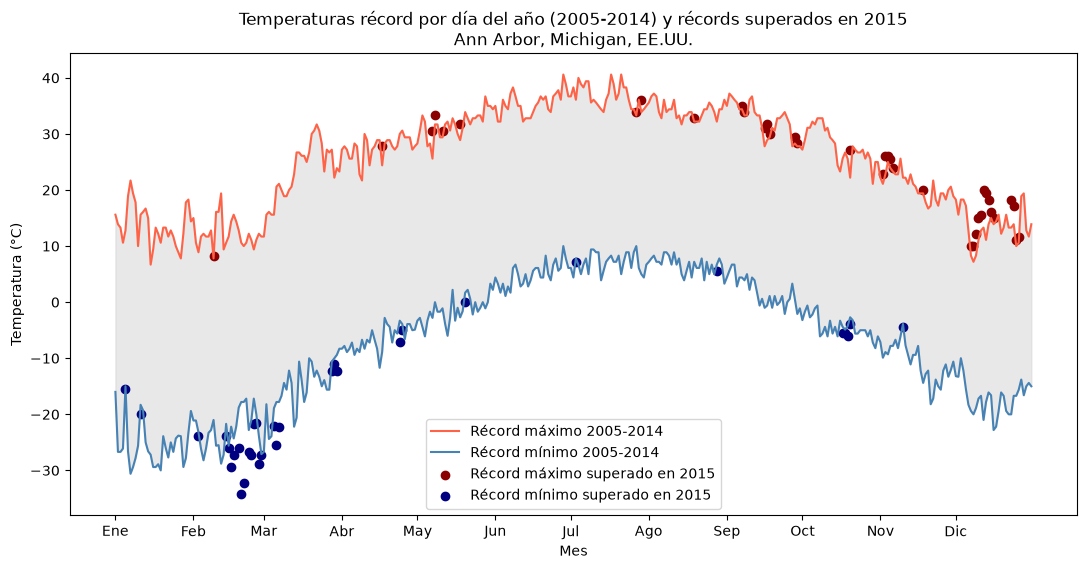

In [14]:
plt.figure(figsize=(13, 6))

plt.plot(maximas.index, maximas.values, color='tomato', label='Récord máximo 2005-2014')
plt.plot(minimas.index, minimas.values, color='steelblue', label='Récord mínimo 2005-2014')
plt.fill_between(maximas.index, minimas.values, maximas.values, color='lightgray', alpha=0.5)

plt.scatter(records_max_2015.index, records_max_2015.values, color='darkred', marker='o',
            label='Récord máximo superado en 2015')
plt.scatter(records_min_2015.index, records_min_2015.values, color='navy', marker='o',
            label='Récord mínimo superado en 2015')

meses = ['01-01', '02-01', '03-01', '04-01', '05-01', '06-01',
         '07-01', '08-01', '09-01', '10-01', '11-01', '12-01']
nombres_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
                 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
plt.xticks(meses, nombres_meses)

plt.title('Temperaturas récord por día del año (2005-2014) y récords superados en 2015\n'
          'Ann Arbor, Michigan, EE.UU.')
plt.xlabel('Mes')
plt.ylabel('Temperatura (°C)')
plt.legend(loc='lower center')
plt.show()

### Conclusiones
En 2015 se superaron 37 récords de temperatura máxima y 32 de temperatura mínima respecto al período 2005-2014. Los récords de frío se concentran entre febrero y marzo, mientras que los récords de calor aparecen principalmente en diciembre, lo que indica un invierno inicial más frío y un final de año más cálido que lo registrado en la década anterior.